# Fig. S4: tight-binding LDOS for no doping and for doping of the opposite sign


    Top-layer LDOS along a line across the (+⁴−) strip embedded in (+⁵) (the geometry of Fig. 3),
    calculated without the substrate-induced on-site terms (`no_onsite`) and with on-site terms of the
    opposite sign (`opposite_sign`), with the energy derivative of each.

    Data: `ldos_system1_layer6_{case}.npy` (LDOS(E, x), E = −0.4995 … 0.4995 eV in 1 meV steps) and
    `x_system1_layer6_{case}.npy` (x in Å). File layer 6 is the top layer.


Paper: Kandrai, K. *et al.* One-way electron mirrors from single-layer stacking shifts in rhombohedral graphite. Preprint at https://arxiv.org/abs/2610.20905 (2026).

In [1]:
import os
import sys
import requests
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

In [2]:
print('python', sys.version.split()[0])
print('numpy', np.__version__)
print('matplotlib', matplotlib.__version__)

python 3.13.5
numpy 2.3.1
matplotlib 3.10.3


In [3]:
# figure style of the paper: scienceplots if it is installed, plain matplotlib otherwise
try:
    import scienceplots  # noqa: F401
    plt.style.use(['science', 'no-latex', 'nature', 'std-colors'])
except ImportError:
    pass
matplotlib.rcParams['pdf.fonttype'] = 42   # editable text in Inkscape / Illustrator
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 110

In [4]:
# Data files are downloaded from Zenodo into DATA_DIR if they are not there yet.
ZENODO_RECORD = '23419464'   # record number of the data set, https://zenodo.org/records/<ZENODO_RECORD>
DATA_DIR = 'data'

FILES = ['ldos_system1_layer6_no_onsite.npy', 'x_system1_layer6_no_onsite.npy', 'ldos_system1_layer6_opposite_sign.npy', 'x_system1_layer6_opposite_sign.npy']


def get_data(filename, record=ZENODO_RECORD, data_dir=DATA_DIR):
    """Return the local path of a data file, downloading it from Zenodo first if needed."""
    path = os.path.join(data_dir, filename)
    if os.path.exists(path):
        return path
    os.makedirs(data_dir, exist_ok=True)
    url = f'https://zenodo.org/records/{record}/files/{requests.utils.quote(filename)}?download=1'
    print(f'Downloading {filename} ...')
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(path, 'wb') as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    print(f'  saved to {path}')
    return path


for f in FILES:
    get_data(f)

  saved to data/ldos_system1_layer6_no_onsite.npy
  saved to data/x_system1_layer6_no_onsite.npy
  saved to data/ldos_system1_layer6_opposite_sign.npy
  saved to data/x_system1_layer6_opposite_sign.npy


In [5]:
def extent_of(da, xdim, ydim):
    """imshow extent (outer pixel edges) of an xarray DataArray with uniform coordinates."""
    x, y = da[xdim].values, da[ydim].values
    dx = (x[-1] - x[0]) / (x.size - 1)
    dy = (y[-1] - y[0]) / (y.size - 1)
    return [x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2]


def extent_xy(x, y):
    """imshow extent (outer pixel edges) for two uniform coordinate arrays."""
    dx = (x[-1] - x[0]) / (x.size - 1)
    dy = (y[-1] - y[0]) / (y.size - 1)
    return [x[0] - dx / 2, x[-1] + dx / 2, y[0] - dy / 2, y[-1] + dy / 2]

In [6]:
CASES = {'no_onsite': 'no doping', 'opposite_sign': 'doping of the opposite sign'}
E = np.arange(-0.4995, 0.5, 0.001)
Elim = 0.4
E_mask = (E >= -Elim) & (E <= Elim)
E_crop = E[E_mask]


def load_case(case):
    ldos = np.load(get_data(f'ldos_system1_layer6_{case}.npy'))
    x = np.load(get_data(f'x_system1_layer6_{case}.npy'))
    assert ldos.shape[0] == E.size
    return (x - x[0]) / 10, ldos


cases = {case: load_case(case) for case in CASES}

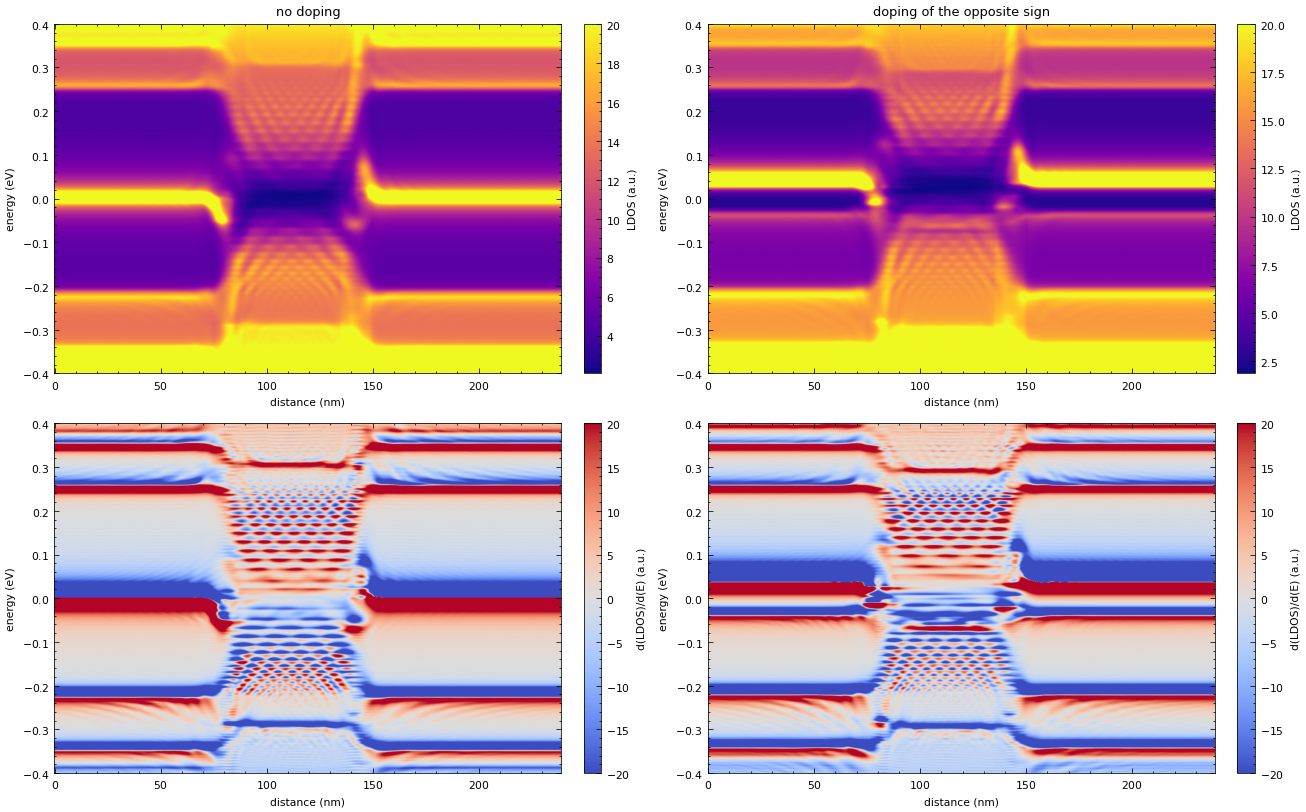

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5))
for j, (case, title) in enumerate(CASES.items()):
    dist_nm, ldos = cases[case]
    grad = np.gradient(ldos, E, axis=0) * 100
    extent = extent_xy(dist_nm, E_crop)
    im = axs[0, j].imshow(ldos[E_mask, :] * 1000, cmap='plasma', aspect='auto', origin='lower',
                          extent=extent, vmin=None, vmax=20)
    axs[0, j].set_title(title)
    fig.colorbar(im, ax=axs[0, j], fraction=0.046, pad=0.04).set_label('LDOS (a.u.)')
    im = axs[1, j].imshow(grad[E_mask, :], cmap='coolwarm', aspect='auto', origin='lower',
                          extent=extent, vmin=-20, vmax=20)
    fig.colorbar(im, ax=axs[1, j], fraction=0.046, pad=0.04).set_label('d(LDOS)/d(E) (a.u.)')
    for ax in axs[:, j]:
        ax.set_xlabel('distance (nm)'); ax.set_ylabel('energy (eV)')
plt.tight_layout()
plt.show()